John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

Import Packages

In [13]:
library(tidyverse)
library(tidymodels)
library(rpart.plot)
library(vip)
library(ranger)

set.seed(42)
MODEL_NAME <- "candidate_match_with_focal_song_types"


Load candidate-level data exported by notebook 2

In [14]:
candidate_files <- list.files("data/by_id", pattern = "_candidate_classification\\.csv$", full.names = TRUE)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

model_data_by_male <- flatten(map(candidate_files, function(candidate_file) {
    song_data <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- song_data %>% pull(male_number) %>% as.character() %>% unique() %>% na.omit()
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    map(focal_numbers, function(focal_number) {
        focal_rows <- song_data %>% filter(as.character(male_number) == focal_number)
        male_prefix <- paste0("M", focal_number)
        required_columns <- c("event_id", "candidate_ust", "match", "candidate_n_ust_window", paste0("candidate_matches_", male_prefix, "_1_last_UST"), paste0("candidate_matches_", male_prefix, "_2_last_UST"), paste0(male_prefix, "_1_last_UST"), paste0(male_prefix, "_2_last_UST"), paste0("time_since_", male_prefix, "_1_last_song"), paste0("time_since_", male_prefix, "_2_last_song"))
        missing_columns <- setdiff(required_columns, names(focal_rows))
        if (length(missing_columns) > 0) stop(sprintf("Missing required columns in %s for %s: %s", candidate_file, male_prefix, paste(missing_columns, collapse = ", ")))
        focal_rows %>% transmute(
            focal_male = paste0(focal_ids, "_", male_prefix), focal_id = focal_ids, male_number = focal_number, event_id,
            candidate_ust = as.factor(as.character(candidate_ust)), match, candidate_n_ust_window,
            focal_last_1_candidate = .data[[paste0("candidate_matches_", male_prefix, "_1_last_UST")]],
            focal_last_2_candidate = .data[[paste0("candidate_matches_", male_prefix, "_2_last_UST")]],
            focal_last_1_song_type = as.factor(as.character(.data[[paste0(male_prefix, "_1_last_UST")]])),
            focal_last_2_song_type = as.factor(as.character(.data[[paste0(male_prefix, "_2_last_UST")]])),
            focal_time_since_last_1 = .data[[paste0("time_since_", male_prefix, "_1_last_song")]],
            focal_time_since_last_2 = .data[[paste0("time_since_", male_prefix, "_2_last_song")]]
        ) %>% mutate(match_class = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match"))) %>% select(-match)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

walk(model_data_by_male, function(male_data) {
    event_checks <- male_data %>% group_by(event_id) %>% summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) stop(sprintf("Invalid candidate events for %s", unique(male_data$focal_male)))
})

In [15]:
map_dfr(model_data_by_male, ~ .x %>% summarise(
    focal_male = first(focal_male),
    n_events = n_distinct(event_id),
    n_candidate_rows = n(),
    n_song_types = n_distinct(candidate_ust)
))

focal_male,n_events,n_candidate_rows,n_song_types
<chr>,<int>,<int>,<int>
DgTbO_M5,1167,32676,28
DgTbO_M6,999,27972,28
KLgK_M5,516,9804,19
KRDg_M2,1021,26546,26
LbOW_M1,699,12582,18
RbDgY_M2,656,13776,21
RRO_M6,535,10165,19
TbTbLg_M4,734,13946,19
TbWY_M1,604,10268,17


Train/test split and cross-validation

In [16]:
male_splits <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data <- map(male_splits, testing)
male_vfolds <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

Data preprocessing using a recipe

In [17]:
male_recipes <- map(male_train_data, ~ recipe(match_class ~ ., data = .x) %>% update_role(focal_male, focal_id, male_number, event_id, candidate_ust, new_role = "id") %>% step_impute_median(all_numeric_predictors()))

Tune using top-1 candidate-selection accuracy

In [18]:
top1_candidate_accuracy <- function(predictions) {
    predictions %>% group_by(event_id) %>% slice_max(.pred_match, n = 1, with_ties = FALSE) %>%
        summarise(correct = any(match_class == "match"), .groups = "drop") %>%
        summarise(top1_accuracy = mean(correct)) %>% pull(top1_accuracy)
}

tune_grid <- tidyr::crossing(mtry = c(1, 2, 3, 4, 5), min_n = c(2, 5, 10, 15, 20))
fit_one_male <- function(male_data, train_data, test_data, vfolds, model_recipe) {
    focal_male <- unique(male_data$focal_male)
    tuning_results <- map_dfr(seq_len(nrow(tune_grid)), function(i) {
        spec <- rand_forest(mtry = tune_grid$mtry[i], trees = 1000, min_n = tune_grid$min_n[i]) %>% set_engine("ranger", importance = "impurity", probability = TRUE) %>% set_mode("classification")
        wf <- workflow() %>% add_recipe(model_recipe) %>% add_model(spec)
        fold_results <- map_dfr(vfolds$splits, function(split) {
            fit_i <- fit(wf, analysis(split))
            assessment_data <- assessment(split)
            predictions <- predict(fit_i, assessment_data, type = "prob") %>% bind_cols(assessment_data %>% select(event_id, match_class))
            tibble(top1_accuracy = top1_candidate_accuracy(predictions))
        })
        tibble(mtry = tune_grid$mtry[i], min_n = tune_grid$min_n[i], mean_top1_accuracy = mean(fold_results$top1_accuracy), std_error = sd(fold_results$top1_accuracy) / sqrt(nrow(fold_results)))
    }) %>% arrange(desc(mean_top1_accuracy), std_error)
    best_params <- tuning_results %>% slice(1)
    final_spec <- rand_forest(mtry = best_params$mtry, trees = 1000, min_n = best_params$min_n) %>% set_engine("ranger", importance = "impurity", probability = TRUE) %>% set_mode("classification")
    final_model <- workflow() %>% add_recipe(model_recipe) %>% add_model(final_spec) %>% fit(data = train_data)
    test_predictions <- predict(final_model, test_data, type = "prob") %>% bind_cols(test_data %>% select(focal_male, event_id, candidate_ust, match_class))
    event_predictions <- test_predictions %>% group_by(event_id) %>% arrange(desc(.pred_match), .by_group = TRUE) %>% summarise(focal_male = first(focal_male), predicted_song_type = first(candidate_ust), actual_song_type = candidate_ust[match_class == "match"][1], .groups = "drop") %>% mutate(predicted_song_type = factor(predicted_song_type, levels = levels(male_data$candidate_ust)), actual_song_type = factor(actual_song_type, levels = levels(male_data$candidate_ust)))
    ranking_metrics <- test_predictions %>% group_by(event_id) %>% arrange(desc(.pred_match), .by_group = TRUE) %>% mutate(candidate_rank = row_number(), actual_match = match_class == "match") %>% summarise(top1_correct = any(candidate_rank == 1 & actual_match), top3_correct = any(candidate_rank <= 3 & actual_match), reciprocal_rank = 1 / min(candidate_rank[actual_match]), correct_rank = min(candidate_rank[actual_match]), .groups = "drop")
    metrics <- tibble(focal_male = focal_male, n_test_events = nrow(event_predictions), accuracy = mean(ranking_metrics$top1_correct), macro_precision = precision(event_predictions, truth = actual_song_type, estimate = predicted_song_type, estimator = "macro")$.estimate, macro_recall = recall(event_predictions, truth = actual_song_type, estimate = predicted_song_type, estimator = "macro")$.estimate, top3_recall = mean(ranking_metrics$top3_correct), mean_reciprocal_rank = mean(ranking_metrics$reciprocal_rank), mean_rank = mean(ranking_metrics$correct_rank))
    list(focal_male = focal_male, tuning_results = tuning_results, best_params = best_params, model = final_model, test_predictions = test_predictions, event_predictions = event_predictions, metrics = metrics)
}
male_results <- pmap(list(model_data_by_male, male_train_data, male_test_data, male_vfolds, male_recipes), fit_one_male)

Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'154': 2, '155': 0, '157': 0, '158': 0, '159': 0, '160': 0, '161': 0, '162': 0,
'163': 0, '164': 0, '30': 0"
Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'13': 12, '155': 0, '157': 0, '158': 0, '159': 0, '160': 0, '161': 0, '162': 0,
'163': 0, '164': 0, '30': 0, '5': 6"
Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_po

Select best hyperparameters and refit on all training data

In [19]:
map_dfr(male_results, "best_params") %>% select(mtry, min_n, mean_top1_accuracy, std_error)

mtry,min_n,mean_top1_accuracy,std_error
<dbl>,<dbl>,<dbl>,<dbl>
1,15,0.1174996,0.007840794
2,10,0.1702467,0.017415460
1,20,0.1216895,0.017795917
1,5,0.1720280,0.016636891
1,10,0.1697244,0.013503325
1,5,0.1873626,0.019857895
1,5,0.1950991,0.031323090
2,15,0.1304207,0.010279858
1,5,0.1867787,0.013716741


Evaluate held-out test data

In [20]:
per_male_metrics <- map_dfr(male_results, "metrics")
per_male_metrics

focal_male,n_test_events,accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,350,0.1171429,0.08025227,0.09796565,0.2371429,0.2388934,13.340000
DgTbO_M6,300,0.1500000,0.13239551,0.09028847,0.2966667,0.2856284,11.263333
KLgK_M5,155,0.1612903,0.25289978,0.17681895,0.4129032,0.3366048,6.632258
KRDg_M2,306,0.1274510,0.08626032,0.07022270,0.2875817,0.2772987,9.918301
LbOW_M1,210,0.1380952,0.14726747,0.19488255,0.3714286,0.3170072,7.300000
RbDgY_M2,197,0.1878173,0.12573874,0.12283699,0.3959391,0.3566171,6.055838
RRO_M6,161,0.2236025,0.14543866,0.12250848,0.3726708,0.3595867,7.565217
TbTbLg_M4,220,0.1363636,0.11916256,0.10734412,0.3272727,0.2965267,7.386364
TbWY_M1,181,0.2651934,0.20858388,0.21146346,0.5027624,0.4357191,5.027624


In [1]:
male_train_data

ERROR: Error: object 'male_train_data' not found


Confusion matrix

In [21]:
map(male_results, ~ conf_mat(.x$event_predictions, truth = actual_song_type, estimate = predicted_song_type))

$DgTbO_M5
          Truth
Prediction  1 10 11 12 13 15 153 154 155 156 157 158 159 160 161 162 163 164 20
       1    3  1  2  0  0  2   4   0   0   0   0   0   0   0   0   0   0   0 12
       10   4  8  5  1  0  0   4   1   0   0   0   0   0   0   0   0   0   0 13
       11   0  0  0  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  2
       12   0  0  3  1  0  1   0   0   0   0   0   0   0   0   0   0   0   0  3
       13   0  3  1  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  3
       15   0  1  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  2
       153  5  1  0  0  0  0   2   0   0   0   0   0   0   0   0   0   0   0  3
       154  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       155  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       156  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       157  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       158  0 

Feature importance

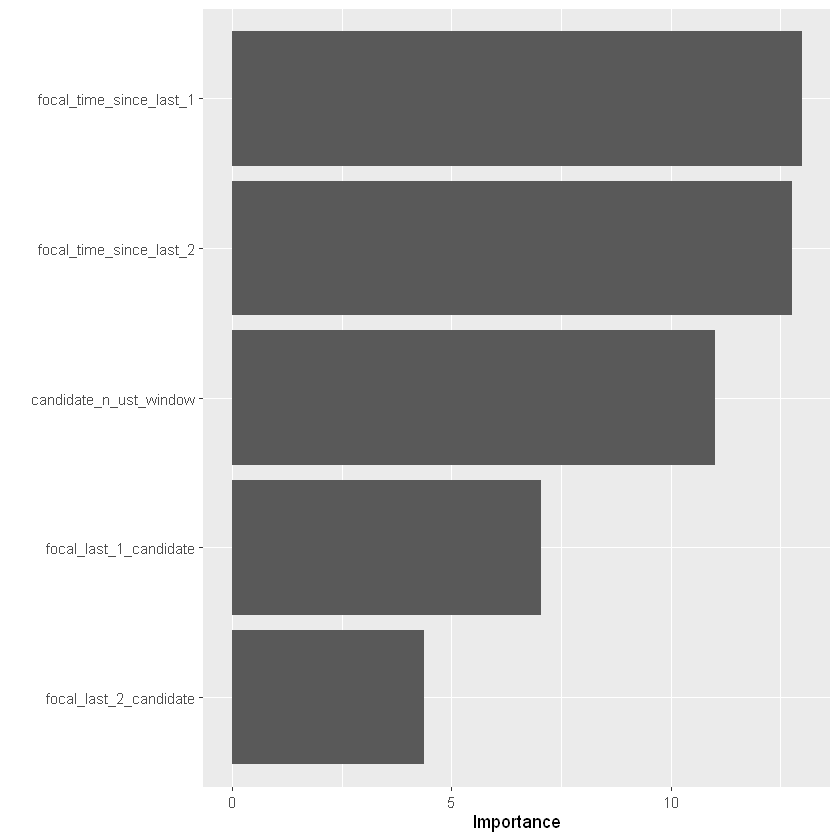

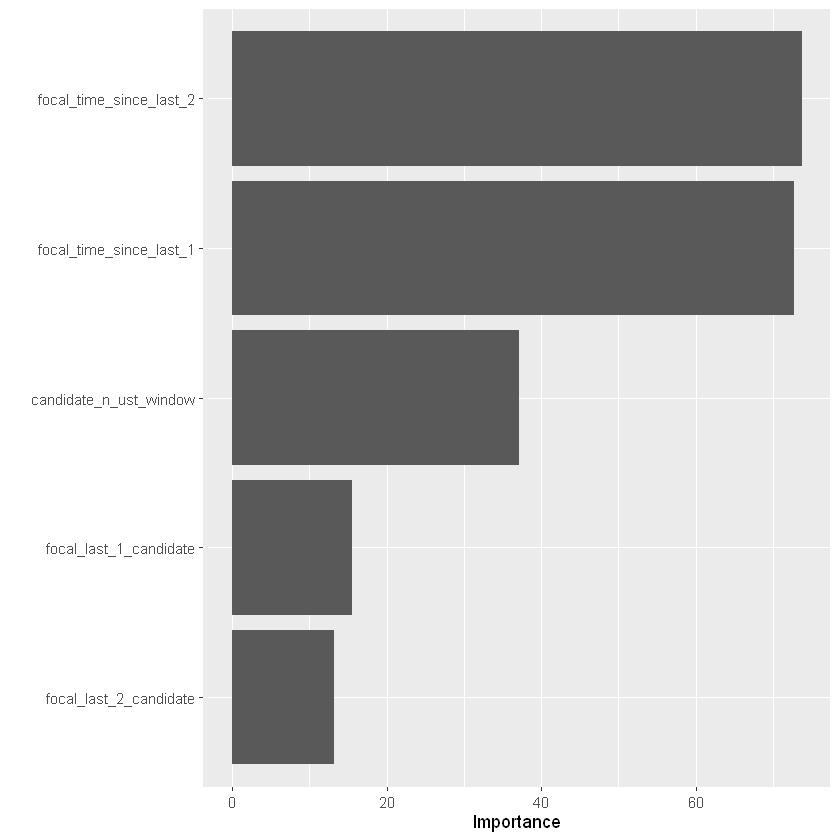

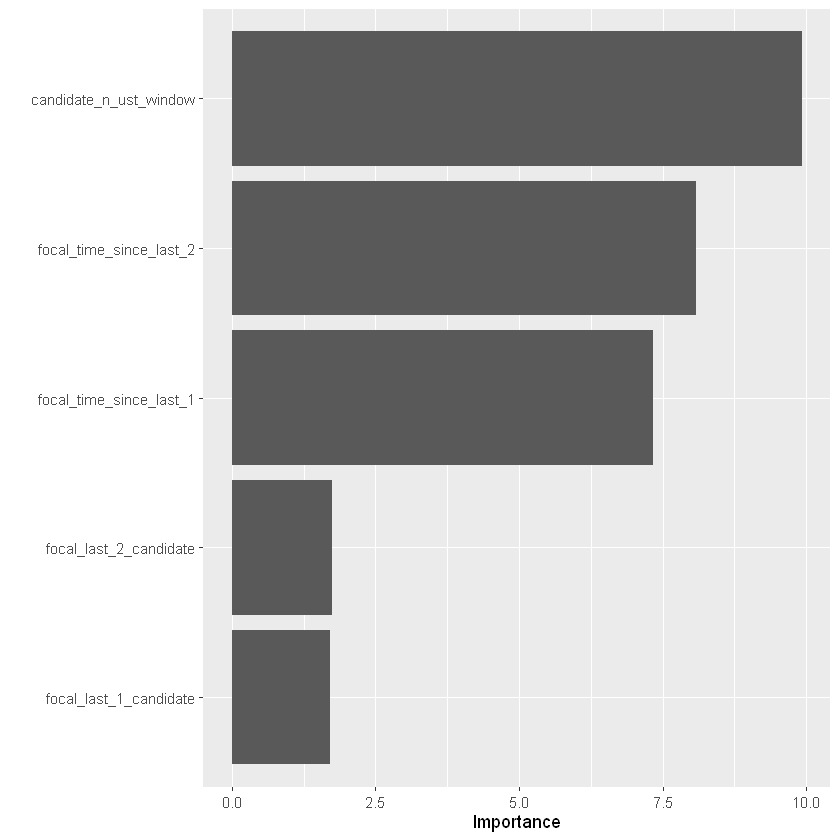

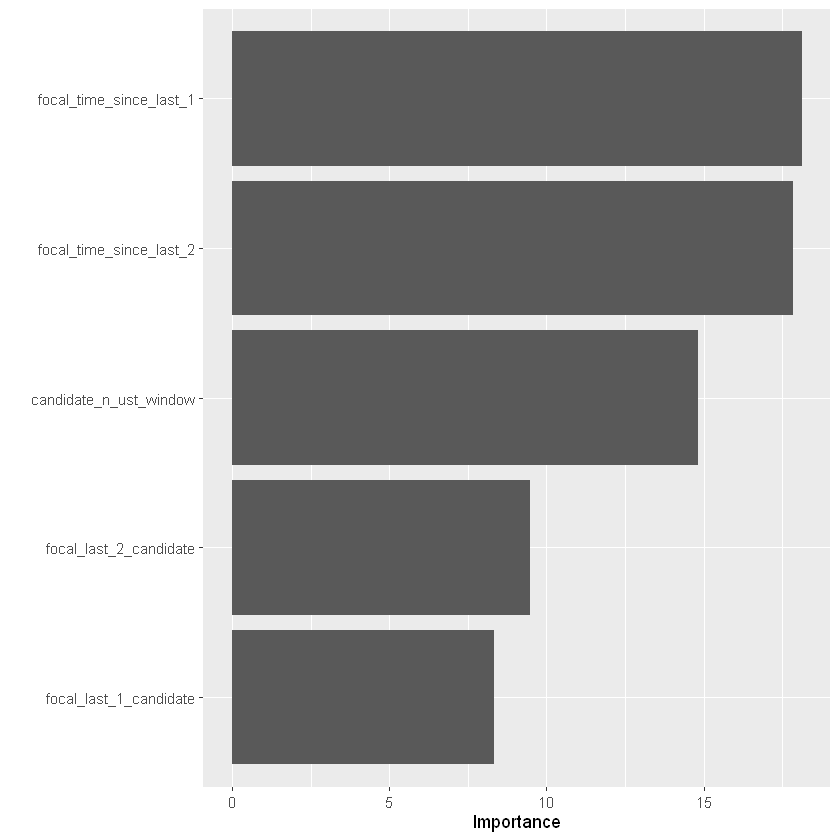

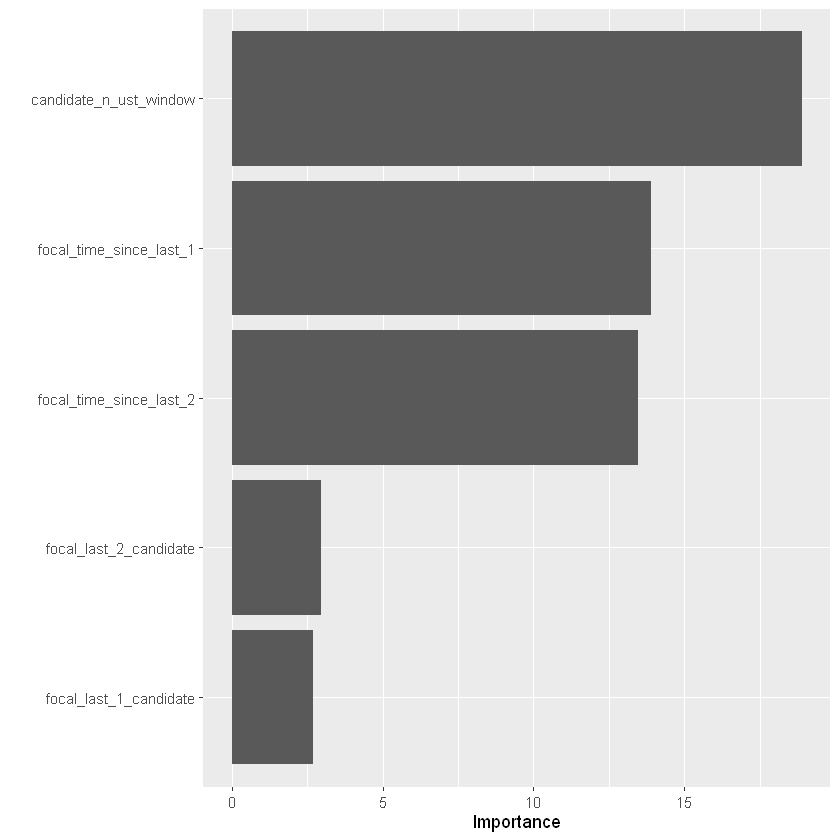

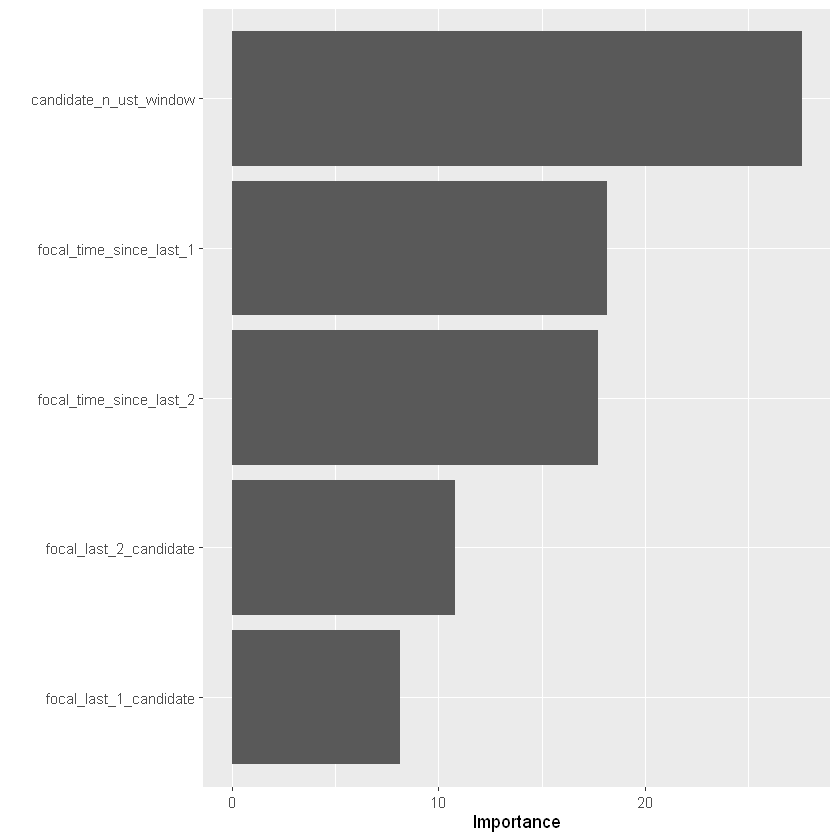

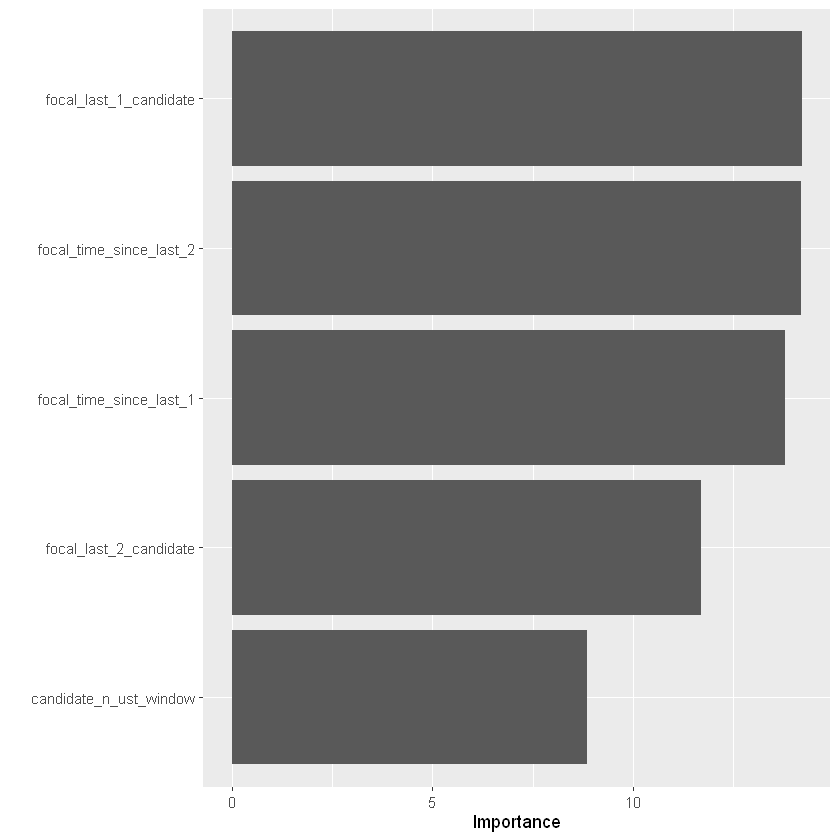

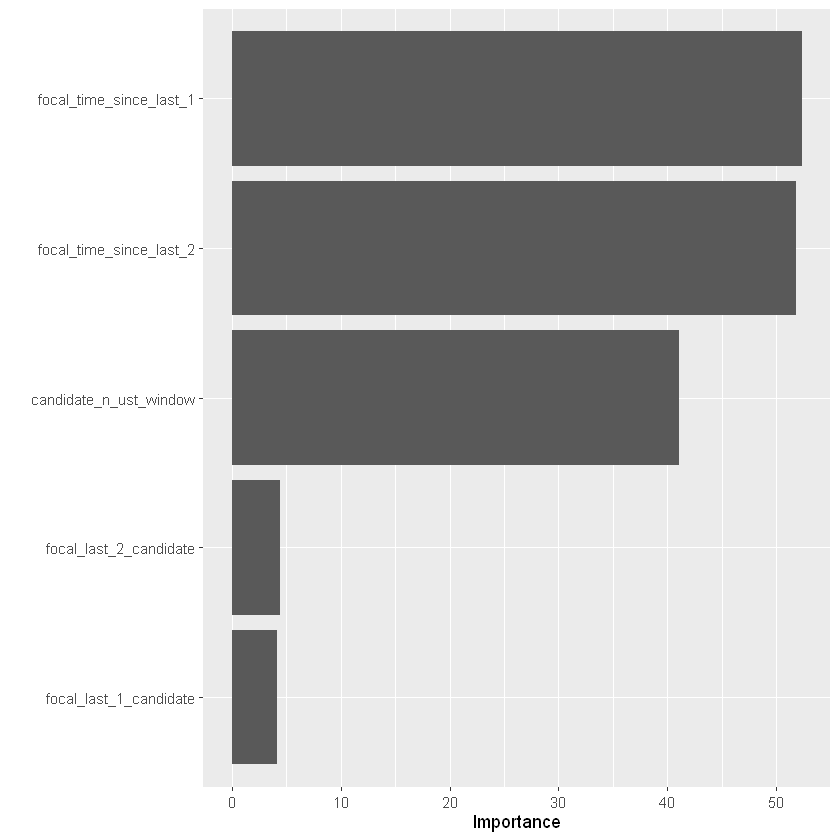

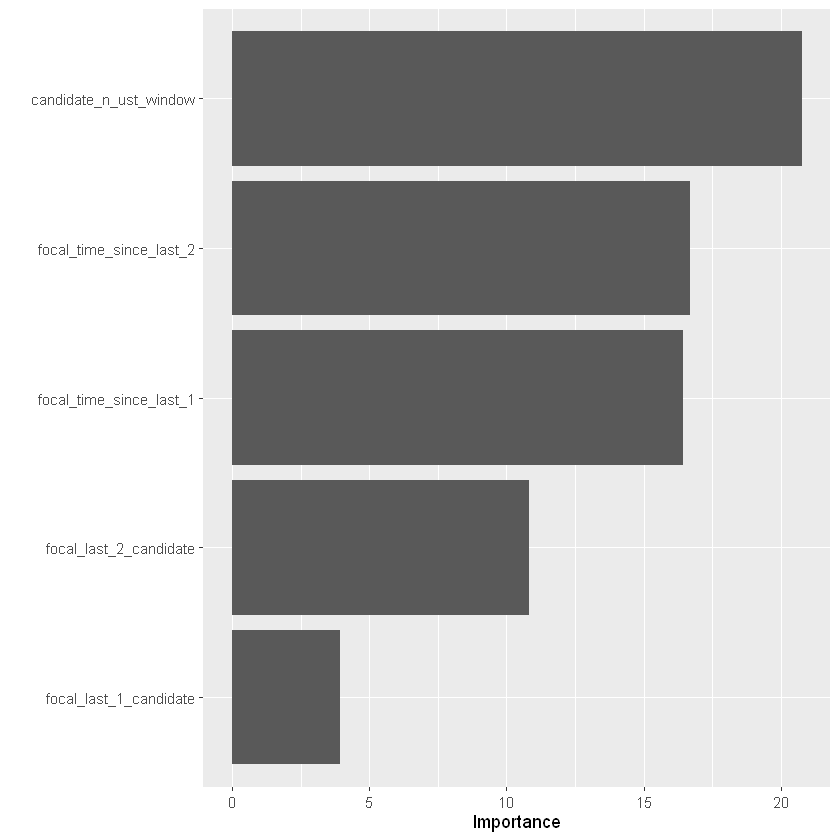

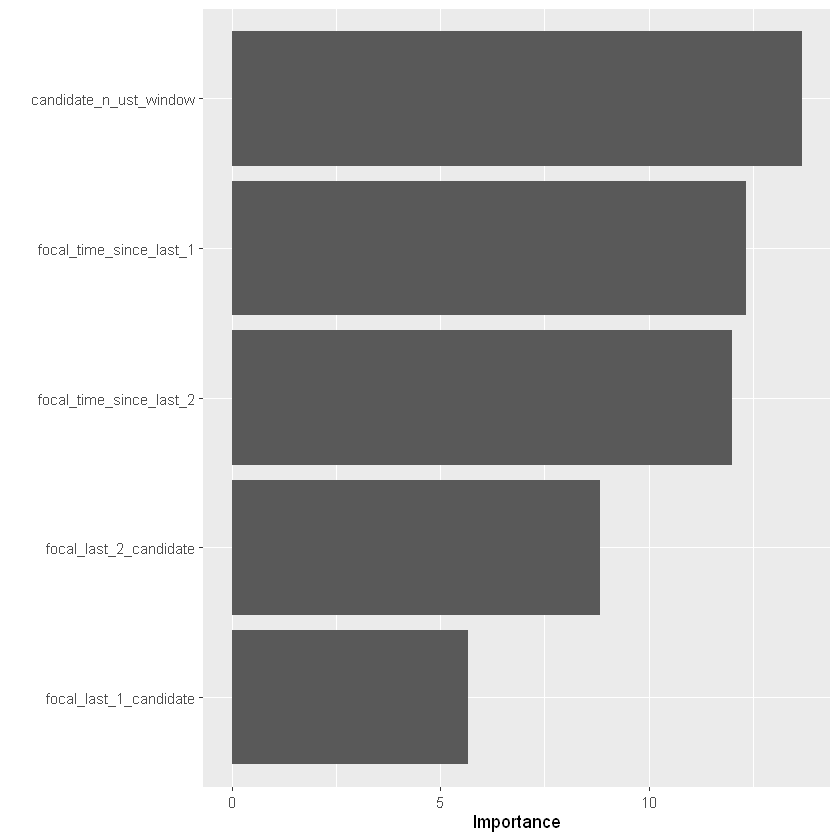

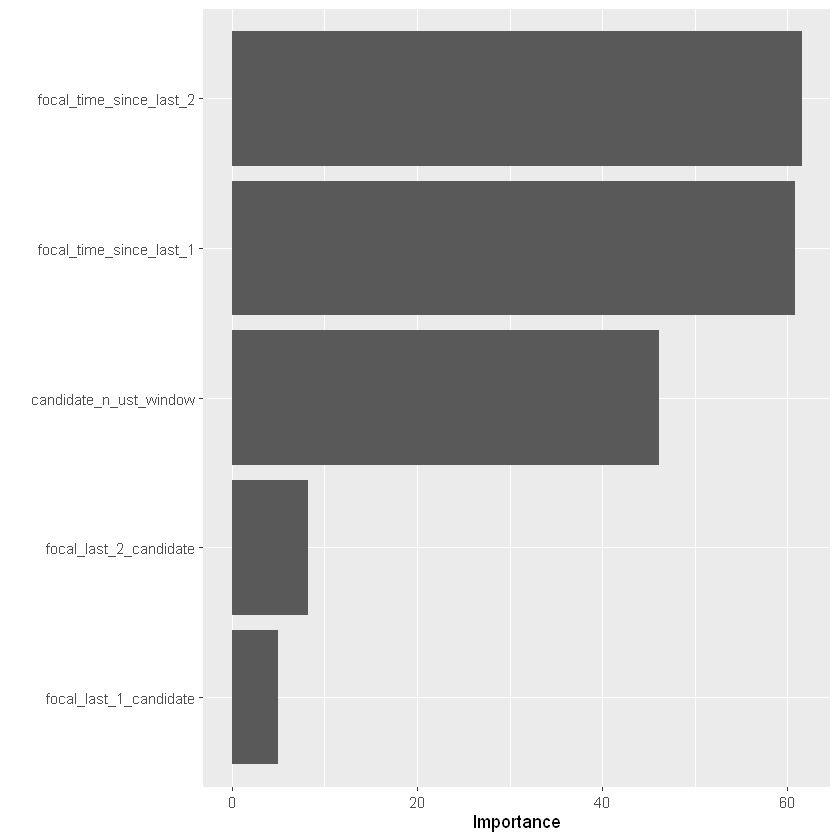

In [22]:
walk(male_results, ~ print(vip(.x$model %>% extract_fit_engine(), num_features = 5)))

Candidate-ranking metrics

In [23]:
per_male_metrics %>% summarise(macro_accuracy = mean(accuracy), macro_top3_recall = mean(top3_recall), macro_mean_reciprocal_rank = mean(mean_reciprocal_rank), macro_mean_rank = mean(mean_rank))

macro_accuracy,macro_top3_recall,macro_mean_reciprocal_rank,macro_mean_rank
<dbl>,<dbl>,<dbl>,<dbl>
0.1668261,0.3517994,0.3210778,8.290182


In [24]:
# Save model results using the model name defined above.
dir.create("data/2026_results", recursive = TRUE, showWarnings = FALSE)

per_male_metrics <- map_dfr(male_results, "metrics")
all_event_predictions <- map_dfr(male_results, ~ .x$event_predictions)
all_tuning_results <- map2_dfr(male_results, names(male_results), ~ .x$tuning_results %>% mutate(focal_male = .y))

write_csv(per_male_metrics, file.path("data/2026_results", paste0(MODEL_NAME, "_test_metrics.csv")))
write_csv(all_event_predictions, file.path("data/2026_results", paste0(MODEL_NAME, "_event_predictions.csv")))
write_csv(all_tuning_results, file.path("data/2026_results", paste0(MODEL_NAME, "_tuning_results.csv")))
saveRDS(male_results, file.path("data/2026_results", paste0(MODEL_NAME, "_models.rds")))

walk(male_results, function(result) {
    importance_chart <- result$model %>%
        extract_fit_engine() %>%
        vip(num_features = 10) +
        labs(title = paste(result$focal_male, MODEL_NAME)) +
        theme_bw()
    ggsave(
        file.path("data/2026_results", paste0(MODEL_NAME, "_", result$focal_male, "_importance.png")),
        plot = importance_chart,
        width = 8,
        height = 6,
        units = "in"
    )
})

per_male_metrics

focal_male,n_test_events,accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,350,0.1171429,0.08025227,0.09796565,0.2371429,0.2388934,13.340000
DgTbO_M6,300,0.1500000,0.13239551,0.09028847,0.2966667,0.2856284,11.263333
KLgK_M5,155,0.1612903,0.25289978,0.17681895,0.4129032,0.3366048,6.632258
KRDg_M2,306,0.1274510,0.08626032,0.07022270,0.2875817,0.2772987,9.918301
LbOW_M1,210,0.1380952,0.14726747,0.19488255,0.3714286,0.3170072,7.300000
RbDgY_M2,197,0.1878173,0.12573874,0.12283699,0.3959391,0.3566171,6.055838
RRO_M6,161,0.2236025,0.14543866,0.12250848,0.3726708,0.3595867,7.565217
TbTbLg_M4,220,0.1363636,0.11916256,0.10734412,0.3272727,0.2965267,7.386364
TbWY_M1,181,0.2651934,0.20858388,0.21146346,0.5027624,0.4357191,5.027624
